# The Thymio escape

For the fall semester of 2025, the 24th team below joined their forces to save Thymio, a small squared-shaped robot lost in its world. To escape, he needs to join the portal as soon as possible and avoid any obstacles in his way.

- 341237 – Louis Grange (vision and report)
- 362819 – Alessandro De Zen (global and local navigation, planning, motion, and filtering)
- 328691 – Verter Stoilov (filtering)

To achieve this hard and dangerous mission, Louis helped Thymio see its environment through Vision and generate reports, while Alessandro, with the help of Verter, guided him through the obscure and deadly areas using Navigation, Motion, and Filtering.

<img src="assets/project.webp" width="325" alt="Picture of Thymio's Adventure" /> <img src="assets/project-cam.webp" width="370" alt="Picture of Thymio's Adventure" />

## Environment

The world of Thymio, displayed below, is composed of
- a light **background**, which is necessary to create a contrast with the black sheets, as we will use a threshold filter in the background. It is also required to guarantee good marker detection in `opencv-python`;
- four aruco **markers** delimiting our map, allowing us to make a projection and therefore avoid any camera-related space distortion;
- black **sheets** as global obstacles, even though we could have chosen any type and shape of object that is black;
- two more **markers** for the robot and the target, from which we can easily take the position and angle thanks to `opencv-python`;
- a **paper cylinder** as a local obstacle, which must be high enough to be seen by the robot (represented by the metal bottle in the image below).

<img src="./assets/environment.webp" width="500" />

We think this setup covers all our needs with the least code necessary, because we are able to process all the data using the well-known `opencv-python` library, which already does a lot of work by itself.

In [16]:
from src.vision import *
from src.consts import *
from src.motion import *
from src.utils import *
from src.navigation import *

## Vision

The vision part focuses on getting all the available information on the real world, such as robot position, global obstacles, and map delimitations. To do this, we divided the vision task into multiple smaller steps. Inside the codebase, it is visible in the [`vision.step`](src/vision.py) method.

<img src="./assets/vision-gif.webp" width="500" />

1. Connection to camera and image acquisition
2. Aruco markers detection using `opencv-python`
3. Projection using aruco markers position
4. Target and robot position and orientation processing
5. Final grid building, which will be used by other modules afterward

We now describe each of these steps in a dedicated section in more depth. As the first step is quite straightforward, it will be skipped.

### Markers detection

One of the reasons we chose this setup is to be able to use `cv2.detectMarkers`, which will do a lot of work for us in this step. With `opencv-python` we get the coordinate of each four corners for the six markers, from which we can easily deduct the map delimitations. We can also compute the robot direction by using two points $p_0$ and $p_1$ of the 5th marker and $\theta = \text{atan2}(p_0 - p_1)$ (axix conventions are developed later).

#### Lock

We had to use an auto-lock system for different reasons, such as
- preventing computation of the path at each frame, which is very resource-consuming;
- ensuring a non-compromised grid (the robot is always correctly placed onto the map), because without the lock sometimes our camera didn't catch the markers and the projection could not happen;
This system is represented by [`vis.lock`](src/vision.py), and its purpose is to freeze the perspective matrix.

### Projection

<img src="./assets/projection.webp" width="500" />

Since the camera is a single point of view, the default `raw_frame` it generated dilates the space. To fix this, we need to zoom in the main map, represented by the quadrilateral built using the center of each four aruco markers. It is done inside the [`aruco_projection`](src/vision.py) method.

Each pixel is projected using a transformation matrix obtained with `cv2.getPerspectiveTransform`. Each pixel position is assigned to a new pixel position inside the projected frame.

### Grid building

Once we have all the information about Thymio and the projection, we need to define a grid that other modules will be able to use, representing the different areas of our map (obstacles, void, or near-obstacle cells), done inside the [`build_grid`](src/vision.py) method.

1. First, we turn our projected image into a gray level (value 0-255) image using `cv2.cvtColor` to lower the dimensions from 3D (BGR) to 2D (grayscale).

    <img src="./assets/environment-gray.webp" width="250" alt="Step 1" />

2. We then filter this grayscale frame with `cv2.bilateralFilter`. The bilateral filter keeps the contrast (edges) while removing the noise as much as possible inside the shapes. In the frame below, we see an improvement on the edges, which guarantees a good reading of our black shapes on our white background as obstacles. The `cv2.gaussianBlur` would have blurred the edges, and is therefore not suited.

    <img src="./assets/environment-filtered.webp" width="250" alt="Step 2" />
3. Then, we apply the `cv2.threshold` function to get a binary image (each pixel is either white or black)

    <img src="./assets/environment-threshold.webp" width="250" alt="Step 3" />

     Note that we used the `cv2.THRESH_BINARY_INV` and not `cv2.THRESH_BINARY`, but it is totally arbitrary and would not change anything (other than testing for white instead of black in the next step).
4. Finally, we build a grid onto the threshold frame. Our grid has smaller dimensions than the original frame due to the cost of computing high-dimensional arrays. To lower these dimensions, we group pixels together and compute their average (from 0, black, to 255, white). If this value is greater than a specific constant (meaning it's white), we consider this an obstacle. Otherwise, we consider this cell as void.

    <img src="./assets/cell-average.webp" width="350" alt="Step 4" />

Because the robot's position is computed from the marker's center (which corresponds to the robot's center), a safety buffer must be defined around obstacles that the robot is forbidden to enter to prevent collisions.

We therefore have the final grid rendered into our `cv2` window.

<img src="./assets/grid.webp" width="350" alt="Grid" />

Below is a code that you can try to see the different steps of the vision processing:
1. Raw image form the camera
2. Grayscale conversion
3. Bilateral filter application
4. Binary threshold application

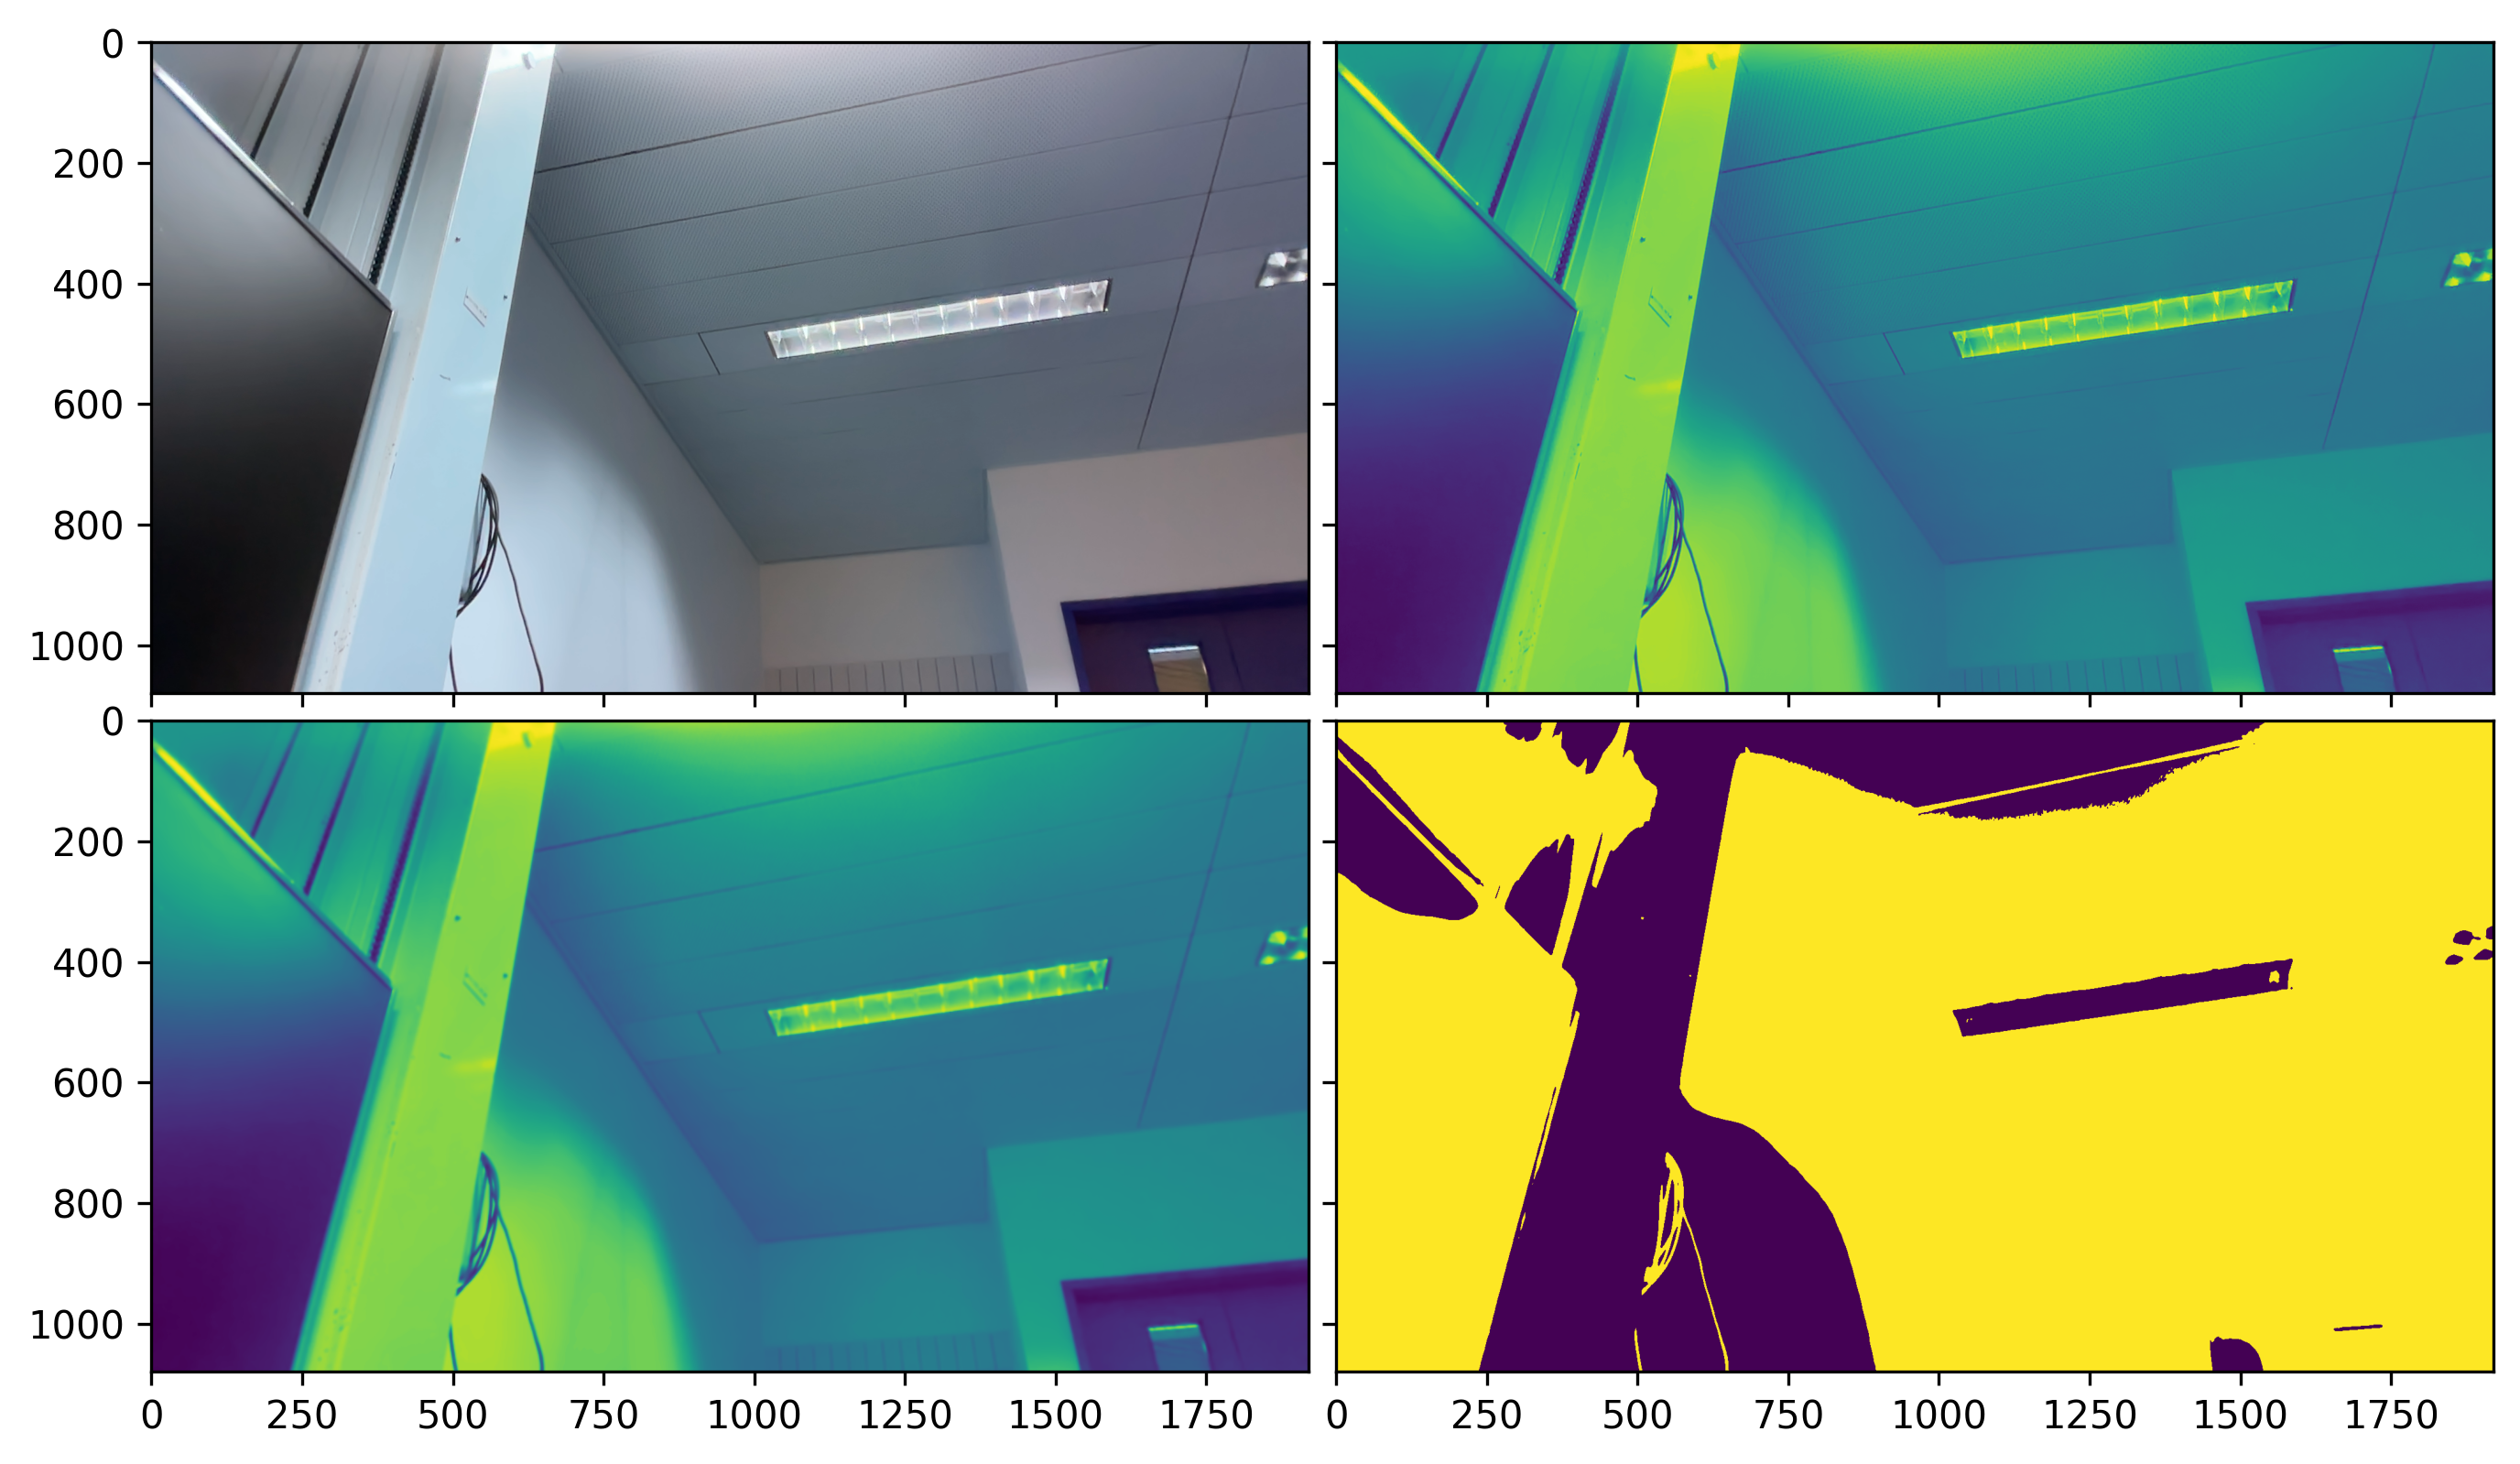

In [ ]:
import matplotlib.pyplot as plt
import cv2
from mpl_toolkits.axes_grid1 import ImageGrid
from time import sleep
from src.vision import Vision
from src.consts import *

vis = Vision(camera=1)
sleep(3)
vis.capture()

im1 = vis.raw_frame
im2 = cv2.cvtColor(im1, cv2.COLOR_BGR2GRAY)
im3 = cv2.bilateralFilter(im2, VISION_FILTER_DIAM, VISION_FILTER_SIGMA_COLOR, VISION_FILTER_SIGMA_SPACE)
_, im4 = cv2.threshold(im3, VISION_TRESH, VISION_TRESH_MAX, cv2.THRESH_BINARY_INV)

fig = plt.figure(figsize=(11, 11))
fig.set_dpi(300)

grid = ImageGrid(fig, 111, nrows_ncols=(2, 2), axes_pad=0.1)

for ax, im in zip(grid, [im1, im2, im3, im4]):
    ax.imshow(im)

vis.release()

## Navigation

### Motion

We started by defining a common convention for cartesian coordinates, displayed below.

<img src="./assets/axis.webp" alt="Axis" width="400" />

To make the robot follow the path found, we implemented a simple [`global_controller`](src/motion.py). The robot first rotates to face its next waypoint (the construction of the list of waypoints, the plan, is explained later); this is done by our [`align`](src/motion.py) method. Once aligned, it moves forward until it reaches the waypoint. This process is repeated until the robot reaches the final destination.

To make the motion smoother, we decided to implement a direction threshold ([`ANGLE_TOLERANCE`](src/consts.py)), shown above, which allows a small alignment error at all times. We chose a value of 0.2 radians. By doing so, we avoid oscillations around the target while keeping good accuracy and a simple controller. We also defined a distance threshold ([`DISTANCE_TOLERANCE`](src/consts.py)) to consider the robot has reached its waypoint. This has also been implemented to avoid oscillations when the robot is very close to its target. For the final waypoint (reaching the portal), we set a lower distance tolerance ([`DISTANCE_TOLERANCE_FINAL`](src/consts.py)) and angle tolerance ([`ANGLE_TOLERANCE_FINAL`](src/consts.py)) to ensure the robot reaches the portal with good accuracy.

### Global path-finding

For the global path-finding part, we tried different algorithms using the [web-app shown in class](https://qiao.github.io/PathFinding.js/visual/). We then chose the A-star algorithm, for three reasons:
- it is **complete**, meaning it will always find a path if one exists;
- it is **optimal** and therefore always gives the shortest path to destination;
- it is **efficient** thanks to its use of an evaluation function $f(n)$ (in opposition with Best-First-Search algorithms, for example).
    $$ f(n) = g(n) + h(n) $$
    with $g(n)$ the cost to the current node, $h(n)$ the cost from the current node to the target, and $f(n)$ the total cost. A-star gives priority to paths that have a low total cost $f(n)$, therefore avoiding unnecessarily exploring some parts of the map.

To implement it, we did not use a library but adapted it ourselves from the [JavaScript AStarFinder from qiao](https://github.com/qiao/PathFinding.js/blob/master/src/finders/AStarFinder.js).

The optimal part is optional, but we absolutely needed our path-finding algorithm to be complete, as we did not want our robot to freeze because of a bad choice of path-finding.

 We selected the Chebyshev distance as our heuristic function $h(n)$, which defines the distance between two points $p_1$ and $p_2$ as the maximum of the absolute coordinate difference.

$$ D(p_1, p_2) = \max (|x_1 - x_2|, |y_1 - y_2|) $$

We've chosen this function because we want Thymio to be able to move in eight directions (diagonal, vertical, and horizontal), and the Chebyshev distance represents the minimum steps required in these directions to achieve the goal.

<img src="./assets/path.webp" width="600" />

In the image above, the path is shown in dark gray, but it cannot be used as it is because the robot is not accurate enough to reach exactly every single point. We therefore defined a plan, displayed in orange, constructed by taking only the path steps that are just before a change in direction. We use this plan to give the robot its next waypoints. You can see below the function that builds this plan from the path generated by [`a_star`](src/navigation.py).

In [18]:
def generate_plan_and_path(self, start, end):
    """
    Generate waypoints and full path from start to end.
    Waypoints are generated at direction changes.
    
    Args:
        start: Starting position
        end: Goal position
        
    Returns:
        Tuple of (waypoints, full_path)
    """
    path = []

    if end is not None:
        path = self.a_star(start, end)

    if not (len(path) > 0):
        return ([], [])

    path = path[1:]

    # Extract waypoints at direction changes
    plan = []
    previous_direction = None
    for i in range(1, len(path)):
        current_direction = (path[i][0] - path[i - 1][0],
                                path[i][1] - path[i - 1][1])
        if current_direction != previous_direction:
            plan.append(path[i - 1])
            previous_direction = current_direction
    plan = plan[1:]
    plan.append(end)
    return (plan, path)

You can play with our path-planning module by executing the code below (we used it to test the module) to see the path found (yellow) by [`a_star`](src/navigation.py) and the corresponding plan (orange). You can add/remove obstacles by clicking on the grid/dragging the mouse. You can also move arround the start (green) and end (red) points by dragging them. Make sure to be in an environment with the _requirements.txt_ installed.

In [1]:
# 's' to start the A-star path finding
# 'q' to quit
!python -m src.navigation

### Local Obstacle Avoidance

We implemented the [`local_controller`](src/motion.py) method in [`motion.py`](src/motion.py), that performs obstacle avoidance using a **potential field** approach. This method combines two potential forces that act on the robot.

- **Attractive** force, which pulls the robot toward the next waypoint. We computed the angular difference between the robot's orientation $theta$ and the direction of the goal and also tuned the attractive gain which we then applied to this angle.

- **Repulsive** force, which pushes the robot away from near obstacles detected by the front proximity sensors. Each of the sensors has a fixed angle $\varphi_i$ relative to the robot's forward direction (±30°, ±15°, 0°).
    For each sensor we normalized its proximity value, then we computed a repulsive magnitude which is proportional to the proximity value. We also created a logic so that the robot turns away from the sensor direction.

We blended these forces by using two weights:
- `obstacle_weight` which increases when obstacles are close;
- `goal_weight = max(0.3, 1 - obstacle_weight) × 0.45` that always keeps a minimum attraction so that the robot never stops aiming its next waypoint.

Therefore, the repulsion dominates when obstacles are close, and goal attraction dominates when the path is clear. The final combined steering command then is:

$$
\text{turn}_{\text{cmd}}
=
k_{\text{goal}} \cdot \varphi
\;+\;
k_{\text{rep}} \cdot (\text{repulsive turn})
$$
where the repulsive turn is proportional to the value of the proximity sensors, and $\varphi$ the angle betweeen the robot's orientation and the goal.

The robot exits local avoidance mode when all five proximity sensors readings remain null for a fixed number of iterations (in our case we set it to 30).  This prevents oscillations between local and global navigation and ensures that the robot fully clears a given obstacle before resuming into global navigation.

## Filtering

The goal of the filtering is to give the robot an as accurate as possible estimation of its position and angle based on the camera and the Thymio PWM commands measurements. The filter compensates for situations where the camera cannot be used to find the robot's position (e.g., the marker is hidden from the camera). We therefore use odometry, meaning the Thymio gets an estimation of its position and orientation only from the Thymio PWM commands.

```Python
# Thymio PWM command, left motor
motor.left.speed
# Thymio PWM command, right motor
motor.right.speed
```

<img src="./assets/variance.webp" width="700" alt="Variance" />

The plots above show the speed variance, and were generated by making our Thymio move forward during 180 seconds. We can see the average at 100, which was the original speed command.

We selected an Extended Kalman Filter (EKF) because the characteristics of our system fit the assumptions of Kalman filtering:

- sensor noises are approximately Gaussian;

- sensor noises are time invariant (white noise);

- sensor noise has a zero mean;

- the system dynamics are nonlinear, but the first-order linearization of the EKF is accurate enough for the project's constraints.

We also choose this filter because in our testing it gave good results.

0. Matrices Q and R are initialized. They represent the noises of the encoders and the camera, and we will need them in the computation of the uncertainty matrices, as well as the Kalman Gain. Their computation is showed in the paragraph **Fine-tuning** below.

$$ Q_t = \begin{pmatrix}
\sigma^2_\text{position} & 0 & 0 & 0 & 0 \\
0 & \sigma^2_\text{position} & 0 & 0 & 0 \\
0 & 0 & \sigma^2_\text{angle} & 0 & 0\\
0 & 0 & 0 & \sigma^2_{L,\text{speed}} & 0 \\
0 & 0 & 0 & 0 & \sigma^2_{R,\text{speed}}
\end{pmatrix} $$

$$ R = \begin{pmatrix}
\sigma^2_\text{position} & 0 & 0 \\
0 & \sigma^2_\text{position} & 0 \\
0 & 0 & \sigma^2_\text{angle}
\end{pmatrix} $$



1. The state vector, corresponding to [`ThymioEKF.x`](src/kalman.py), is defined as
    $$
   \mathbf{\mu}_{t-1} =
    \begin{pmatrix}
    x \\
    y \\
    \theta\\
    v_L\\
    v_R
    \end{pmatrix}
    $$
    with $v_L$ and $v_R$ the respective left and right motor PWM commands.
2. We compute speeds
    $$ v = \dfrac{v_L + v_R}{2} \qquad \omega = \dfrac{v_L - v_R}{L} $$
   with $L$ the distance between the wheels
3. The predicted (_a priori_) state
    $$ \bar{\mathbf{\mu}}_t = \mathbf{\mu}_{t-1} + \begin{pmatrix}
    \Delta x \\
    \Delta y \\
    \Delta \theta\\
    0 \\
    0
    \end{pmatrix} = \mathbf{\mu}_{t-1} + \begin{pmatrix}
    v \cos{\theta} \cdot \Delta t \\
    v \sin{\theta} \cdot \Delta t \\
    \omega \cdot \Delta t \\
    0 \\
    0
    \end{pmatrix} $$
4. We then compute the Jacobian matrix
    $$
    G_t =
    \begin{pmatrix}
    1 & 0 & -v \sin(\theta) \Delta t & 0.5 \cos(\theta) \Delta t & 0.5 \cos(\theta) \Delta t \\
    0 & 1 & v \cos(\theta) \Delta t & 0.5 \sin(\theta) \Delta t & 0.5 \sin(\theta) \Delta t \\
    0 & 0 & 1 & \Delta t / L & - \Delta t / L \\
    0 & 0 & 0 & 1 & 0 \\
    0 & 0 & 0 & 0 & 1 \\
    \end{pmatrix}
    $$
5. We compute the predicted covariance matrix $\bar{\Sigma}_t$, which will be used in the next main loop iteration as $\Sigma_{t-1}$
    $$\bar{\Sigma}_t = G_t \Sigma_{t-1} G_t^T + Q_t$$

While we were testing and adjusting the filter parameters, we noticed that the filter was not giving good results when the robot was in the _alligning_ phase, especially when the camera was covered. Meaning the model's predictions were diverging from the real orientation of the robot. To fix this, we added a parameter _rotation_ to the filter that indicates if the robot is in the _allign_ phase or _forward_ phase. When the robot is in the _alligning_ phase, we increase the model's angular velocity by a factor 12. This corresponds to using two different motion models depending on the phase of the robot (one for translations and one for rotations), which greatly improved the results.

We show on our GUI the uncertainty ellipse corresponding to 1 standard deviation of the position estimate.

<img src="./assets/kalman.webp" width="700" alt="Kalman" />

## Fine-tuning

- We used the _localization-map.pdf_ from the exercise session to get a conversion ratio from the PWM commands of the Thymio to the speed in mm/s.
$$
k = 0.41095
$$
- We then logged raw data from the PWM commands (`motor.left.speed`, `motor.right.speed`) for a given time period and compared it with the expected data in a constant-velocity experiment. In this way, we obtained the variance of the Thymio's speed (PWM commands) and also computed the position and angle variances:
$$
\sigma^2_\text{position} = \sigma^2_\text{speed} \cdot \Delta t \qquad
\sigma^2_\text{angle} = \dfrac{2\cdot \sigma^4_\text{speed}}{L^2}\cdot \Delta t^2
$$
Using these values, we were able to derive the process noise matrix $Q$.

Camera uncertainty was computed by keeping the robot still and obtaining the variations in $x$, $y$ and $\theta$. The approximated values are input into the camera noise matrix $R$.

_Note: all the computed variances were retuned again after testing in the real-life environment and small additional noises were added._

## How to run

To execute the project, make sure you have all the dependencies installed as specified in the _requirements.txt_ file. Then, you can run the [`main.py`](main.py) file to see the `cv2` window appear. Please note that you will need the six aruco markers.

In [ ]:
!python main.py

## Conclusion

The final tests showed that our robot could reliably see its environment, avoid obstacles, and reach the portal as intended. Thymio has since gone home, back to its family. He had to be charged for hours after this tremendous adventure!

We wish to thank Professor Mondada and all the assistants for their support and guidance throughout the project.

## Bibliography

- Aruco markers detection: https://docs.opencv.org/4.x/d5/dae/tutorial_aruco_detection.html
- OpenCV GUI: https://docs.opencv.org/4.x/d7/dfc/group__highgui.html
- Path finding: https://github.com/qiao/PathFinding.js/blob/master/src/finders/AStarFinder.js
- Extended Kalman Filter: the slides of Prof. Mondada's course